# Notebook 04 — Fine-tuning and final conventional-skin evaluation

**Project:** skinX — AI-assisted early skin cancer screening for people with albinism in Rwanda.

In Notebook 03, we trained the classification head of three pretrained models: **MobileNetV3Large, EfficientNetB0, and ResNet50**. The image-feature layers stayed frozen. All three models were still improving at the last epoch, so we haven't chosen a winner yet.

This notebook gives **all three models the same next steps**:

1. Load their saved Notebook 03 checkpoints and check the original validation results.
2. Continue training only the classification head, with early stopping.
3. Fine-tune the upper 40 backbone layers with a smaller learning rate.
4. Compare the models on the **same validation images**, including results for each diagnosis and dataset source.
5. If melanoma detection is still weak, try **one** extra training experiment using more weight for melanoma cases.
6. Review the results, choose one model and threshold, and **manually lock** them.
7. Run the untouched conventional test set **once**, only when the decision is final.

**Data:** PAD-UFES Fitzpatrick I–II and MILK10k visible tone 4–5. These are different skin-tone scales, so we call this our *ordinary light-appearing-skin* baseline. It does not confirm that everyone is non-albino.

**Labels:** TARGET = selected cancerous or precancerous lesions. NON_TARGET = selected lesions labelled benign, not necessarily safe or healthy skin. This is research screening, not a diagnosis.

**PWA images are not used here.** We will test and, if possible, adapt the baseline using separate PWA images in Notebook 05. Keep PWA training cases separate from PWA evaluation cases.

## 1. Set up Colab

Use a T4 or L4 GPU. This notebook reads the image paths and checkpoints already saved in Google Drive. We keep a new run folder so the old results are not overwritten.

You can adjust the training settings here **before starting a new run**. Keep them the same across the three models.

In [1]:
from google.colab import drive
from pathlib import Path
import gc
import hashlib
import json
import math
import shutil
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from sklearn.metrics import (
    confusion_matrix, roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve, ConfusionMatrixDisplay
)
from IPython.display import display

drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/SkinX")
SPLIT_DIR = PROJECT_ROOT / "data" / "splits"
NB03_DIR = PROJECT_ROOT / "models" / "runs" / "notebook_03" / "comparison_v1"
OUTPUT_PARENT = PROJECT_ROOT / "models" / "runs" / "notebook_04"
RUN_TAG = "three_models_finetune_v1"  # Use a new name if you repeat this experiment.
RUN_DIR = OUTPUT_PARENT / RUN_TAG

ARCHITECTURES = ["MobileNetV3Large", "EfficientNetB0", "ResNet50"]
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

HEAD_EXTRA_EPOCHS = 15
HEAD_LEARNING_RATE = 3e-4
FINETUNE_EPOCHS = 18
FINETUNE_LEARNING_RATE = 1e-5
FINETUNE_LAST_N = 40
PATIENCE = 5

# This is an exploratory validation requirement, not a clinical standard.
MIN_SPECIFICITY = 0.80

# Try one extra experiment only if melanoma sensitivity is still low.
RUN_MELANOMA_EXPERIMENT = True
MELANOMA_TRIGGER = 0.60
MELANOMA_WEIGHT = 2.0
MELANOMA_EPOCHS = 12

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
if not tf.config.list_physical_devices("GPU"):
    print("No GPU found. Training will be much slower on a CPU.")

Mounted at /content/drive
TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Check the data and saved models

We are keeping the train/validation split from Notebook 02. We check image paths, labels, duplicates, and grouping IDs before we train. We also check that the Notebook 03 models used these exact split files.

**The test file is not opened in this section.**

In [2]:
TRAIN_PATH = SPLIT_DIR / "skinX_train_manifest_v1.csv"
VAL_PATH = SPLIT_DIR / "skinX_val_manifest_v1.csv"
REQUIRED = ["image_id", "filepath", "dataset_source", "diagnostic",
            "binary_label", "label_group", "group_id", "md5_hash"]


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def check_manifest(frame, name):
    missing = sorted(set(REQUIRED) - set(frame.columns))
    if missing:
        raise ValueError(f"{name}: missing columns: {missing}")
    if frame[REQUIRED].isna().any().any():
        raise ValueError(f"{name}: missing values in required columns")
    if not frame["binary_label"].isin([0, 1]).all():
        raise ValueError(f"{name}: labels must be 0 or 1")
    expected = frame["label_group"].map({"NON_TARGET": 0, "TARGET": 1})
    if not frame["binary_label"].eq(expected).all():
        raise ValueError(f"{name}: TARGET/NON_TARGET labels do not match")
    if frame["image_id"].duplicated().any() or frame["md5_hash"].duplicated().any():
        raise ValueError(f"{name}: repeated image IDs or hashes")
    if set(frame["binary_label"]) != {0, 1}:
        raise ValueError(f"{name}: both labels must be present")
    missing_files = [p for p in frame["filepath"] if not Path(p).is_file()]
    if missing_files:
        raise FileNotFoundError(f"{name}: {len(missing_files)} images are missing; first: {missing_files[0]}")


for path in [TRAIN_PATH, VAL_PATH]:
    if not path.is_file():
        raise FileNotFoundError(f"Missing split file: {path}")
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
check_manifest(train_df, "Training")
check_manifest(val_df, "Validation")
for col in ["image_id", "md5_hash", "group_id"]:
    if set(train_df[col]) & set(val_df[col]):
        raise ValueError(f"Training and validation overlap in {col}")

train_hash, val_hash = sha256(TRAIN_PATH), sha256(VAL_PATH)
baseline_paths = {}
for arch in ARCHITECTURES:
    folder = NB03_DIR / arch
    model_path = folder / "best_model.keras"
    config_path = folder / "config.json"
    for p in [model_path, config_path]:
        if not p.is_file():
            raise FileNotFoundError(f"Missing Notebook 03 file: {p}")
    config = json.loads(config_path.read_text(encoding="utf-8"))
    if config.get("architecture") != arch:
        raise ValueError(f"Wrong model recorded in {config_path}")
    if config.get("train_sha256") != train_hash or config.get("validation_sha256") != val_hash:
        raise ValueError(f"{arch} was trained on different split files")
    if tuple(config.get("image_size", ())) != IMG_SIZE:
        raise ValueError(f"{arch} used a different image size")
    baseline_paths[arch] = model_path

# Compute weights from the training labels only. Use the same weights for all models.
counts = train_df["binary_label"].value_counts()
class_weight = {int(c): len(train_df) / (2 * int(counts[c])) for c in (0, 1)}

print("Training images:", len(train_df), "| Validation images:", len(val_df))
print("Class weights:", {k: round(v, 3) for k, v in class_weight.items()})
display(pd.crosstab(train_df["diagnostic"], train_df["dataset_source"], margins=True))

if RUN_DIR.exists():
    raise FileExistsError(f"This run already exists: {RUN_DIR}. Change RUN_TAG to start a fresh run.")
RUN_DIR.mkdir(parents=True)
run_settings = {
    "run_tag": RUN_TAG, "architectures": ARCHITECTURES, "seed": SEED,
    "train_sha256": train_hash, "validation_sha256": val_hash,
    "model_sha256": {a: sha256(p) for a, p in baseline_paths.items()},
    "image_size": IMG_SIZE, "batch_size": BATCH_SIZE,
    "class_weight": class_weight, "head_extra_epochs": HEAD_EXTRA_EPOCHS,
    "head_learning_rate": HEAD_LEARNING_RATE, "finetune_epochs": FINETUNE_EPOCHS,
    "finetune_learning_rate": FINETUNE_LEARNING_RATE,
    "finetune_last_n": FINETUNE_LAST_N, "patience": PATIENCE,
    "min_specificity": MIN_SPECIFICITY,
    "run_melanoma_experiment": RUN_MELANOMA_EXPERIMENT,
    "melanoma_trigger": MELANOMA_TRIGGER,
    "melanoma_weight": MELANOMA_WEIGHT,
    "melanoma_epochs": MELANOMA_EPOCHS,
    "tensorflow": tf.__version__, "numpy": np.__version__, "pandas": pd.__version__,
}
(RUN_DIR / "settings.json").write_text(json.dumps(run_settings, indent=2) + "\n")
print("Results will be saved in:", RUN_DIR)

Training images: 1661 | Validation images: 339
Class weights: {0: 2.904, 1: 0.604}


dataset_source,MILK10K,PAD_UFES_20,All
diagnostic,,,
ACK,0,122,122
AKIEC,47,0,47
BCC,490,425,915
BKL,71,0,71
DF,11,0,11
MEL,88,26,114
NEV,0,24,24
NV,158,0,158
SCC,0,92,92


Results will be saved in: /content/drive/MyDrive/SkinX/models/runs/notebook_04/three_models_finetune_v1


## 3. Load images and measure results

We use the same image loading as Notebook 03: resize with padding to 224 × 224 and keep RGB pixel values between 0 and 255. **Preprocessing and mild augmentation are already inside each saved model**, so we don't add them again.

A score close to 1 means the model leans towards TARGET. We save results at 0.5 for comparison, but later choose a threshold using validation data only.

In [3]:
# Notebook 03 saved this layer inside its ResNet50 model.
# We need the same definition here so Keras can open that model.
@tf.keras.utils.register_keras_serializable(package="SkinX")
class ResNet50Preprocessing(layers.Layer):
    def call(self, images):
        bgr = tf.reverse(images, axis=[-1])
        return bgr - tf.constant([103.939, 116.779, 123.68], dtype=images.dtype)


def load_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize_with_pad(tf.cast(image, tf.float32), *IMG_SIZE)
    return image, tf.cast(label, tf.float32)


def make_dataset(frame, training=False, sample_weights=None):
    paths = frame["filepath"].astype(str).to_numpy()
    labels = frame["binary_label"].to_numpy(dtype="float32")
    if sample_weights is None:
        ds = tf.data.Dataset.from_tensor_slices((paths, labels))
        map_fn = load_image
    else:
        weights = np.asarray(sample_weights, dtype="float32")
        if len(weights) != len(frame):
            raise ValueError("Sample weights and training rows do not match")
        ds = tf.data.Dataset.from_tensor_slices((paths, labels, weights))
        def load_weighted(path, label, weight):
            image, y = load_image(path, label)
            return image, y, weight
        map_fn = load_weighted
    if training:
        # Shuffle file paths first, not decoded images, to avoid using too much RAM.
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(map_fn, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
print("Example batch:", next(iter(train_ds))[0].shape)


def compile_model(model, learning_rate):
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=[
            tf.keras.metrics.BinaryAccuracy(name="accuracy"),
            tf.keras.metrics.Precision(name="precision"),
            tf.keras.metrics.Recall(name="sensitivity"),
            tf.keras.metrics.AUC(name="roc_auc", curve="ROC"),
            tf.keras.metrics.AUC(name="pr_auc", curve="PR"),
        ],
    )


def get_backbone(model, arch):
    # The backbone is the nested Keras model inside the saved classifier.
    name_part = {"MobileNetV3Large": "mobilenetv3", "EfficientNetB0": "efficientnet",
                 "ResNet50": "resnet50"}[arch]
    candidates = [x for x in model.layers
                  if isinstance(x, tf.keras.Model) and name_part in x.name.lower()]
    if len(candidates) != 1:
        raise ValueError(f"Could not find the {arch} backbone in {model.name}")
    return candidates[0]


def metrics_at_threshold(frame, threshold):
    y = frame["binary_label"].to_numpy(dtype=int)
    p = frame["probability_target"].to_numpy(dtype=float)
    pred = (p >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    result = {
        "images": int(len(frame)), "target_images": int(tp + fn),
        "non_target_images": int(tn + fp),
        "true_positives": int(tp), "false_positives": int(fp),
        "true_negatives": int(tn), "false_negatives": int(fn),
        "sensitivity": float(tp / (tp + fn)) if (tp + fn) else None,
        "specificity": float(tn / (tn + fp)) if (tn + fp) else None,
        "threshold": float(threshold),
        "auroc": float(roc_auc_score(y, p)) if len(np.unique(y)) == 2 else None,
        "average_precision": float(average_precision_score(y, p)) if len(np.unique(y)) == 2 else None,
    }
    return result


def group_metrics(frame, threshold, column):
    return pd.DataFrame([
        {column: str(name), **metrics_at_threshold(group, threshold)}
        for name, group in frame.groupby(column, dropna=False)
    ])


CLINICAL_GROUPS = {
    "BCC": "BCC", "SCC": "SCC", "SCCKA": "SCC",
    "MEL": "Melanoma", "ACK": "Actinic keratosis", "AKIEC": "AK / SCC in situ",
    "NEV": "Benign nevus", "NV": "Benign nevus",
    "SEK": "Seborrheic keratosis", "BKL": "Benign keratinocytic lesion",
    "DF": "Dermatofibroma",
}


def clinical_report(frame, threshold):
    copy = frame.copy()
    copy["clinical_group"] = copy["diagnostic"].map(CLINICAL_GROUPS).fillna("Other / review")
    return group_metrics(copy, threshold, "clinical_group")


def choose_threshold(frame):
    # Find the most sensitive cutoff that still meets the validation specificity floor.
    # We calculate AUROC and average precision only once for the chosen cutoff.
    y = frame["binary_label"].to_numpy(dtype=int)
    p = frame["probability_target"].to_numpy(dtype=float)
    if set(y) != {0, 1}:
        raise ValueError("Threshold selection needs both TARGET and NON_TARGET examples")
    choices = np.r_[np.nextafter(float(p.max()), np.inf), np.unique(p)]
    predicted_target = p[None, :] >= choices[:, None]
    positive = y == 1
    negative = ~positive
    sensitivity = predicted_target[:, positive].mean(axis=1)
    specificity = (~predicted_target[:, negative]).mean(axis=1)
    eligible = np.flatnonzero(specificity >= MIN_SPECIFICITY - 1e-12)
    if len(eligible) == 0:
        raise ValueError("No threshold met the validation specificity requirement")
    best_index = max(eligible, key=lambda i: (sensitivity[i], specificity[i], choices[i]))
    return metrics_at_threshold(frame, float(choices[best_index]))


def make_callbacks(best_path):
    return [
        callbacks.ModelCheckpoint(str(best_path), monitor="val_roc_auc",
                                  mode="max", save_best_only=True, verbose=1),
        callbacks.EarlyStopping(monitor="val_roc_auc", mode="max",
                                patience=PATIENCE, restore_best_weights=True, verbose=1),
    ]


def save_history(history, stage_dir):
    history_df = pd.DataFrame(history.history)
    history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
    history_df.to_csv(stage_dir / "history.csv", index=False)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for ax, metric in zip(axes, ["loss", "roc_auc"]):
        ax.plot(history_df["epoch"], history_df[metric], label="train")
        ax.plot(history_df["epoch"], history_df["val_" + metric], label="validation")
        ax.set(xlabel="epoch", title=metric)
        ax.legend()
    fig.tight_layout()
    fig.savefig(stage_dir / "training_curves.png", dpi=150)
    plt.close(fig)


def save_validation(model, stage_key, checkpoint, seconds=None):
    stage_dir = RUN_DIR / stage_key
    if stage_dir.exists() and (stage_dir / "validation_predictions.csv").exists():
        raise FileExistsError(f"Results already saved for {stage_key}")
    stage_dir.mkdir(parents=True, exist_ok=True)
    scores = model.predict(val_ds, verbose=0).reshape(-1)
    if len(scores) != len(val_df) or not np.isfinite(scores).all():
        raise ValueError(f"Invalid validation predictions for {stage_key}")
    preds = val_df.copy()
    preds["probability_target"] = scores
    op = choose_threshold(preds)
    cutoff = op["threshold"]
    preds["prediction_at_0_5"] = (scores >= 0.50).astype(int)
    preds["prediction_at_selected_threshold"] = (scores >= cutoff).astype(int)
    preds["selected_validation_threshold"] = cutoff
    preds.to_csv(stage_dir / "validation_predictions.csv", index=False)
    by_source = group_metrics(preds, cutoff, "dataset_source")
    by_dx = group_metrics(preds, cutoff, "diagnostic")
    by_clinical = clinical_report(preds, cutoff)
    by_source.to_csv(stage_dir / "validation_by_source.csv", index=False)
    by_dx.to_csv(stage_dir / "validation_by_diagnosis.csv", index=False)
    by_clinical.to_csv(stage_dir / "validation_by_clinical_group.csv", index=False)
    if "diagnosis_full" in preds.columns:
        group_metrics(preds, cutoff, "diagnosis_full").to_csv(
            stage_dir / "validation_by_full_diagnosis.csv", index=False)
    summary = {"at_0_5": metrics_at_threshold(preds, 0.50),
               "at_selected_threshold": op, "seconds": seconds,
               "checkpoint": str(checkpoint),
               "model_size_mb": round(Path(checkpoint).stat().st_size / 1024**2, 2)}
    (stage_dir / "validation_metrics.json").write_text(json.dumps(summary, indent=2) + "\n")
    return preds, op


stage_predictions = {}
stage_checkpoints = {}
stage_seconds = {}


def add_stage(stage_key, model, checkpoint, seconds=None):
    stage_predictions[stage_key], _ = save_validation(model, stage_key, checkpoint, seconds)
    stage_checkpoints[stage_key] = Path(checkpoint)
    stage_seconds[stage_key] = seconds


Example batch: (32, 224, 224, 3)


## 4. Continue head training for all three models

The saved models from Notebook 03 are our starting point. First we check their predictions against the old saved results. Then we keep the backbones frozen and train the classifier heads for up to 15 more epochs. Early stopping can end training sooner.

All three get the **same data, learning rate, class weights, and stopping rule**.

In [4]:
for arch in ARCHITECTURES:
    print(f"\n{arch}: checking the Notebook 03 model")
    tf.keras.backend.clear_session()
    gc.collect()
    model = models.load_model(baseline_paths[arch], compile=False)
    backbone = get_backbone(model, arch)
    if model.name != arch:
        raise ValueError(f"Loaded {model.name} instead of {arch}")
    base_key = f"{arch}__baseline"
    add_stage(base_key, model, baseline_paths[arch])

    old_file = NB03_DIR / arch / "validation_predictions.csv"
    if old_file.is_file():
        old = pd.read_csv(old_file)
        if not old["image_id"].astype(str).equals(val_df["image_id"].astype(str)):
            raise ValueError(f"Notebook 03 validation image order differs for {arch}")
        diff = np.max(np.abs(old["probability_target"].to_numpy() -
                             stage_predictions[base_key]["probability_target"].to_numpy()))
        print("Largest prediction difference from Notebook 03:", round(float(diff), 6))
        if diff > 0.02:
            raise ValueError(f"{arch}: old and new predictions do not match closely")

    print("Continuing head training:", arch)
    backbone.trainable = False
    compile_model(model, HEAD_LEARNING_RATE)
    stage_key = f"{arch}__head"
    stage_dir = RUN_DIR / stage_key
    stage_dir.mkdir()  # The save function will reuse this folder.
    best_path = stage_dir / "best_model.keras"
    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=HEAD_EXTRA_EPOCHS,
                        class_weight=class_weight, callbacks=make_callbacks(best_path), verbose=1)
    seconds = round(time.perf_counter() - start, 1)
    save_history(history, stage_dir)
    best = models.load_model(best_path, compile=False)
    add_stage(stage_key, best, best_path, seconds)
    print("Validation AUROC:", round(metrics_at_threshold(stage_predictions[stage_key], 0.5)["auroc"], 4))
    del best, model
    tf.keras.backend.clear_session()
    gc.collect()

print("\nHead training is finished for all three models.")


MobileNetV3Large: checking the Notebook 03 model
Largest prediction difference from Notebook 03: 0.0
Continuing head training: MobileNetV3Large
Epoch 1/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.8797 - loss: 0.3194 - pr_auc: 0.9871 - precision: 0.9633 - roc_auc: 0.9380 - sensitivity: 0.8899
Epoch 1: val_roc_auc improved from None to 0.95296, saving model to /content/drive/MyDrive/SkinX/models/runs/notebook_04/three_models_finetune_v1/MobileNetV3Large__head/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/SkinX/models/runs/notebook_04/three_models_finetune_v1/MobileNetV3Large__head/best_model.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 157s 3s/step - accuracy: 0.8778 - loss: 0.3310 - pr_auc: 0.9858 - precision: 0.9600 - roc_auc: 0.9357 - sensitivity: 0.8895 - val_accuracy: 0.8643 - val_loss: 0.3496 - val_pr_auc: 0.9913 - val_precision: 0.9800 - val_roc_auc: 0.9530 - val_sensitivity: 0.8566
Epoch 2/15
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.8527 

## 5. Fine-tune the upper backbone layers

Now we let the last 40 layers of each backbone learn from our skin-lesion images. We keep the other layers frozen and use a smaller learning rate so we don't change the pretrained features too quickly.

BatchNormalization layers stay frozen. We start each model from its **best head-training checkpoint**, not from scratch.

Using the same number of layers is a simple, consistent rule; the architectures still have different layer sizes. We'll compare the actual results rather than assume this makes them identical.

In [5]:
for arch in ARCHITECTURES:
    print(f"\nFine-tuning: {arch}")
    tf.keras.backend.clear_session()
    gc.collect()
    source_path = stage_checkpoints[f"{arch}__head"]
    model = models.load_model(source_path, compile=False)
    backbone = get_backbone(model, arch)
    if not 0 < FINETUNE_LAST_N <= len(backbone.layers):
        raise ValueError(f"FINETUNE_LAST_N is too large for {arch}")

    backbone.trainable = True
    for layer in backbone.layers[:-FINETUNE_LAST_N]:
        layer.trainable = False
    for layer in backbone.layers[-FINETUNE_LAST_N:]:
        layer.trainable = not isinstance(layer, layers.BatchNormalization)

    print("Trainable backbone layers:", sum(int(layer.trainable) for layer in backbone.layers))
    compile_model(model, FINETUNE_LEARNING_RATE)
    stage_key = f"{arch}__finetuned"
    stage_dir = RUN_DIR / stage_key
    stage_dir.mkdir()
    best_path = stage_dir / "best_model.keras"
    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS,
                        class_weight=class_weight, callbacks=make_callbacks(best_path), verbose=1)
    seconds = round(time.perf_counter() - start, 1)
    save_history(history, stage_dir)
    best = models.load_model(best_path, compile=False)
    add_stage(stage_key, best, best_path, seconds)
    op = choose_threshold(stage_predictions[stage_key])
    print("Validation sensitivity:", round(op["sensitivity"], 3),
          "| Specificity:", round(op["specificity"], 3))
    del model, best
    tf.keras.backend.clear_session()
    gc.collect()

print("\nFine-tuning is finished for all three models.")


Fine-tuning: MobileNetV3Large
Trainable backbone layers: 32
Epoch 1/18
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.8769 - loss: 0.3108 - pr_auc: 0.9877 - precision: 0.9708 - roc_auc: 0.9448 - sensitivity: 0.8776
Epoch 1: val_roc_auc improved from None to 0.95441, saving model to /content/drive/MyDrive/SkinX/models/runs/notebook_04/three_models_finetune_v1/MobileNetV3Large__finetuned/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/SkinX/models/runs/notebook_04/three_models_finetune_v1/MobileNetV3Large__finetuned/best_model.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 144ms/step - accuracy: 0.8609 - loss: 0.3344 - pr_auc: 0.9850 - precision: 0.9658 - roc_auc: 0.9330 - sensitivity: 0.8625 - val_accuracy: 0.8791 - val_loss: 0.3232 - val_pr_auc: 0.9916 - val_precision: 0.9730 - val_roc_auc: 0.9544 - val_sensitivity: 0.8811
Epoch 2/18
51/52 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.8740 - loss: 0.3329 - pr_auc: 0.9844 - precision: 0.9662 - roc_auc: 0.9326 

## 6. Look at the fine-tuned results

First compare the fine-tuned models and check their diagnosis-level results. An overall high score can hide missed melanoma cases. The results from PAD-UFES and MILK10k also need to be checked separately.

The threshold in each row is chosen from validation data to reach at least 80% specificity. **That 80% is a research choice, not a medically approved safety level.** The validation set is small, so don't read small differences as proof that one model is better.

In [6]:
def stage_row(key):
    pred = stage_predictions[key]
    op = choose_threshold(pred)
    mel = pred[pred["diagnostic"] == "MEL"]
    melanoma = metrics_at_threshold(mel, op["threshold"])
    return {
        "stage": key, "architecture": key.split("__")[0],
        "threshold": op["threshold"], "auroc": op["auroc"],
        "average_precision": op["average_precision"],
        "sensitivity": op["sensitivity"], "specificity": op["specificity"],
        "false_negatives": op["false_negatives"],
        "melanoma_detected": melanoma["true_positives"],
        "melanoma_images": melanoma["target_images"],
        "melanoma_sensitivity": melanoma["sensitivity"],
        "model_size_mb": round(stage_checkpoints[key].stat().st_size / 1024**2, 2),
        "training_seconds": stage_seconds[key],
    }


fine_keys = [f"{arch}__finetuned" for arch in ARCHITECTURES]
fine_comparison = pd.DataFrame([stage_row(key) for key in fine_keys])
fine_comparison = fine_comparison.sort_values(
    ["sensitivity", "auroc"], ascending=False).reset_index(drop=True)
display(fine_comparison.round(4))
fine_comparison.to_csv(RUN_DIR / "fine_tuned_comparison.csv", index=False)

for key in fine_keys:
    print("\n", key, "— results by diagnosis")
    threshold = choose_threshold(stage_predictions[key])["threshold"]
    display(group_metrics(stage_predictions[key], threshold, "diagnostic")
            [["diagnostic", "images", "target_images", "non_target_images",
              "sensitivity", "specificity", "false_negatives", "false_positives"]]
            .round(3))
    print("Results by dataset source:")
    display(group_metrics(stage_predictions[key], threshold, "dataset_source")
            [["dataset_source", "images", "sensitivity", "specificity"]].round(3))

,stage,architecture,threshold,auroc,average_precision,sensitivity,specificity,false_negatives,melanoma_detected,melanoma_images,melanoma_sensitivity,model_size_mb,training_seconds
0,ResNet50__finetuned,ResNet50,0.3842,0.9551,0.9915,0.9406,0.8113,17,6,16,0.3750,211.25,77.5
1,MobileNetV3Large__finetuned,MobileNetV3Large,0.3890,0.9544,0.9916,0.9196,0.8113,23,3,16,0.1875,27.07,43.6
2,EfficientNetB0__finetuned,EfficientNetB0,0.3683,0.9504,0.9904,0.9196,0.8868,23,3,16,0.1875,31.83,121.7



 MobileNetV3Large__finetuned — results by diagnosis


,diagnostic,images,target_images,non_target_images,sensitivity,specificity,false_negatives,false_positives
0,ACK,29,29,0,1.000,NaN,0,0
1,AKIEC,7,7,0,1.000,NaN,0,0
2,BCC,198,198,0,0.955,NaN,9,0
3,BKL,10,0,10,NaN,0.500,0,5
4,DF,3,0,3,NaN,0.667,0,1
5,MEL,16,16,0,0.188,NaN,13,0
6,NEV,5,0,5,NaN,0.800,0,1
7,NV,32,0,32,NaN,1.000,0,0
8,SCC,20,20,0,0.950,NaN,1,0
9,SCCKA,16,16,0,1.000,NaN,0,0


Results by dataset source:


,dataset_source,images,sensitivity,specificity
0,MILK10K,189,0.889,0.867
1,PAD_UFES_20,150,0.951,0.500


...

,dataset_source,images,sensitivity,specificity
0,MILK10K,189,0.875,0.956
1,PAD_UFES_20,150,0.965,0.500



 ResNet50__finetuned — results by diagnosis


,diagnostic,images,target_images,non_target_images,sensitivity,specificity,false_negatives,false_positives
0,ACK,29,29,0,1.000,NaN,0,0
1,AKIEC,7,7,0,1.000,NaN,0,0
2,BCC,198,198,0,0.970,NaN,6,0
3,BKL,10,0,10,NaN,0.300,0,7
4,DF,3,0,3,NaN,1.000,0,0
5,MEL,16,16,0,0.375,NaN,10,0
6,NEV,5,0,5,NaN,0.600,0,2
7,NV,32,0,32,NaN,1.000,0,0
8,SCC,20,20,0,1.000,NaN,0,0
9,SCCKA,16,16,0,0.938,NaN,1,0


Results by dataset source:


,dataset_source,images,sensitivity,specificity
0,MILK10K,189,0.924,0.844
1,PAD_UFES_20,150,0.958,0.625


## 7. One extra experiment if melanoma is still poorly detected

Our training labels contain far more BCC images than melanoma images. The normal class weights only balance TARGET against NON_TARGET; they do not give melanoma extra attention.

We will try **one** simple follow-up if the best fine-tuned candidate detects fewer than 60% of validation melanomas at its selected threshold. We use a 2× weight for melanoma **in the training set only**. We do not change any labels or move images between splits.

This experiment starts from one fine-tuned candidate, not all three. Its result is compared with the original fine-tuned models on the same validation set. If it doesn't help, we keep the standard result.

In [7]:
# Choose the fine-tuned candidate by overall validation sensitivity first,
# then AUROC to break ties. This does not lock a final model.
weighted_source_key = str(fine_comparison.iloc[0]["stage"])
weighted_source = stage_predictions[weighted_source_key]
weighted_op = choose_threshold(weighted_source)
mel = weighted_source[weighted_source["diagnostic"] == "MEL"]
mel_result = metrics_at_threshold(mel, weighted_op["threshold"])
print("Candidate for the extra experiment:", weighted_source_key)
print("Melanoma detected:", mel_result["true_positives"], "/", mel_result["target_images"])

if not RUN_MELANOMA_EXPERIMENT:
    print("Extra melanoma experiment is turned off.")
elif mel_result["sensitivity"] is None or mel_result["sensitivity"] >= MELANOMA_TRIGGER:
    print("Skipping the extra experiment. The preset melanoma trigger was not met.")
else:
    arch = weighted_source_key.split("__")[0]
    tf.keras.backend.clear_session()
    gc.collect()
    model = models.load_model(stage_checkpoints[weighted_source_key], compile=False)
    backbone = get_backbone(model, arch)
    backbone.trainable = True
    for layer in backbone.layers[:-FINETUNE_LAST_N]:
        layer.trainable = False
    for layer in backbone.layers[-FINETUNE_LAST_N:]:
        layer.trainable = not isinstance(layer, layers.BatchNormalization)

    weights = train_df["binary_label"].map(class_weight).to_numpy(dtype="float32")
    weights[train_df["diagnostic"].eq("MEL").to_numpy()] *= MELANOMA_WEIGHT
    weights /= weights.mean()
    weighted_train_ds = make_dataset(train_df, training=True, sample_weights=weights)
    compile_model(model, FINETUNE_LEARNING_RATE)
    stage_key = f"{arch}__melanoma_weighted"
    stage_dir = RUN_DIR / stage_key
    stage_dir.mkdir()
    best_path = stage_dir / "best_model.keras"
    start = time.perf_counter()
    history = model.fit(weighted_train_ds, validation_data=val_ds, epochs=MELANOMA_EPOCHS,
                        callbacks=make_callbacks(best_path), verbose=1)
    seconds = round(time.perf_counter() - start, 1)
    save_history(history, stage_dir)
    best = models.load_model(best_path, compile=False)
    add_stage(stage_key, best, best_path, seconds)
    print("Extra experiment finished. Compare it with the original fine-tuned model below.")
    del model, best
    tf.keras.backend.clear_session()
    gc.collect()

Candidate for the extra experiment: ResNet50__finetuned
Melanoma detected: 6 / 16
Epoch 1/12
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.9153 - loss: 0.2643 - pr_auc: 0.9929 - precision: 0.9813 - roc_auc: 0.9680 - sensitivity: 0.9146
Epoch 1: val_roc_auc improved from None to 0.94930, saving model to /content/drive/MyDrive/SkinX/models/runs/notebook_04/three_models_finetune_v1/ResNet50__melanoma_weighted/best_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/SkinX/models/runs/notebook_04/three_models_finetune_v1/ResNet50__melanoma_weighted/best_model.keras
52/52 ━━━━━━━━━━━━━━━━━━━━ 19s 187ms/step - accuracy: 0.9157 - loss: 0.2511 - pr_auc: 0.9937 - precision: 0.9768 - roc_auc: 0.9707 - sensitivity: 0.9200 - val_accuracy: 0.8879 - val_loss: 0.2996 - val_pr_auc: 0.9901 - val_precision: 0.9769 - val_roc_auc: 0.9493 - val_sensitivity: 0.8881
Epoch 2/12
52/52 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.9188 - loss: 0.2079 - pr_auc: 0.9954 - precision: 0.98

## 8. Compare every stage and choose a model

This table includes the original Notebook 03 models, the extra head-training models, the fine-tuned models, and the optional melanoma experiment if it ran.

**Do not pick a winner from AUROC alone.** Check melanoma, other cancer labels, benign lesions, performance by source, and model size. Results from just a few examples are uncertain.

The notebook **does not choose and lock a model automatically**. Review this table first. Then enter the chosen stage name and set `LOCK_SELECTION = True` in the next section.

In [8]:
comparison = pd.DataFrame([stage_row(key) for key in stage_predictions])
comparison = comparison.sort_values(["sensitivity", "auroc"], ascending=False)
comparison.to_csv(RUN_DIR / "all_stage_comparison.csv", index=False)
print("Validation comparison (not the final test):")
display(comparison.round(4))

for key in fine_keys + [k for k in stage_predictions if k.endswith("__melanoma_weighted")]:
    threshold = choose_threshold(stage_predictions[key])["threshold"]
    clinical_report(stage_predictions[key], threshold).to_csv(
        RUN_DIR / f"{key}_clinical_groups.csv", index=False)
    group_metrics(stage_predictions[key], threshold, "dataset_source").to_csv(
        RUN_DIR / f"{key}_source_groups.csv", index=False)

print("\nAvailable choices:")
for key in stage_predictions:
    print(" -", key)

Validation comparison (not the final test):


,stage,architecture,threshold,auroc,average_precision,sensitivity,specificity,false_negatives,melanoma_detected,melanoma_images,melanoma_sensitivity,model_size_mb,training_seconds
4,ResNet50__baseline,ResNet50,0.1910,0.9545,0.9913,0.9441,0.8113,16,6,16,0.3750,90.64,NaN
8,ResNet50__finetuned,ResNet50,0.3842,0.9551,0.9915,0.9406,0.8113,17,6,16,0.3750,211.25,77.5
3,EfficientNetB0__head,EfficientNetB0,0.3750,0.9476,0.9899,0.9406,0.8113,17,4,16,0.2500,16.27,85.6
2,EfficientNetB0__baseline,EfficientNetB0,0.3346,0.9460,0.9895,0.9406,0.8113,17,4,16,0.2500,16.28,NaN
5,ResNet50__head,ResNet50,0.2633,0.9557,0.9916,0.9371,0.8302,18,6,16,0.3750,90.64,100.7
0,MobileNetV3Large__baseline,MobileNetV3Large,0.4290,0.9515,0.9910,0.9231,0.8113,22,3,16,0.1875,12.11,NaN
9,ResNet50__melanoma_weighted,ResNet50,0.3559,0.9495,0.9902,0.9231,0.8679,22,8,16,0.5000,211.25,50.0
6,MobileNetV3Large__finetuned,MobileNetV3Large,0.3890,0.9544,0.9916,0.9196,0.8113,23,3,16,0.1875,27.07,43.6
1,MobileNetV3Large__head,MobileNetV3Large,0.3933,0.9538,0.9915,0.9196,0.8113,23,3,16,0.1875,12.10,212.1
7,EfficientNetB0__finetuned,EfficientNetB0,0.3683,0.9504,0.9904,0.9196,0.8868,23,3,16,0.1875,31.83,121.7



Available choices:
 - MobileNetV3Large__baseline
 - MobileNetV3Large__head
 - EfficientNetB0__baseline
 - EfficientNetB0__head
 - ResNet50__baseline
 - ResNet50__head
 - MobileNetV3Large__finetuned
 - EfficientNetB0__finetuned
 - ResNet50__finetuned
 - ResNet50__melanoma_weighted


## 9. Lock the final model and threshold (manual step)

**Stop and review the validation comparison before running this part.**

When you are ready, copy the stage name you choose into `CHOSEN_STAGE` and change `LOCK_SELECTION` to `True`. That saves an unchanged copy of the checkpoint and the threshold chosen from validation. It also records which training and validation files we used.

If the results are not good enough to support a screening claim, you can leave this step off and report the limitations. Don't look at the test set to decide what to change.

Locked: EfficientNetB0__head
Validation threshold: 0.37495
Saved the model and selection details. The test set is still sealed.
Results by clinical group:


,clinical_group,images,target_images,non_target_images,true_positives,false_positives,true_negatives,false_negatives,sensitivity,specificity,threshold,auroc,average_precision
0,AK / SCC in situ,7,7,0,7,0,0,0,1.000,NaN,0.375,None,None
1,Actinic keratosis,29,29,0,29,0,0,0,1.000,NaN,0.375,None,None
2,BCC,198,198,0,193,0,0,5,0.975,NaN,0.375,None,None
3,Benign keratinocytic lesion,10,0,10,0,3,7,0,NaN,0.700,0.375,None,None
4,Benign nevus,37,0,37,0,3,34,0,NaN,0.919,0.375,None,None
5,Dermatofibroma,3,0,3,0,1,2,0,NaN,0.667,0.375,None,None
6,Melanoma,16,16,0,4,0,0,12,0.250,NaN,0.375,None,None
7,SCC,36,36,0,36,0,0,0,1.000,NaN,0.375,None,None
8,Seborrheic keratosis,3,0,3,0,3,0,0,NaN,0.000,0.375,None,None


Results by source:


,dataset_source,images,target_images,non_target_images,true_positives,false_positives,true_negatives,false_negatives,sensitivity,specificity,threshold,auroc,average_precision
0,MILK10K,189,144,45,130,4,41,14,0.903,0.911,0.375,0.943,0.983
1,PAD_UFES_20,150,142,8,139,6,2,3,0.979,0.250,0.375,0.914,0.995


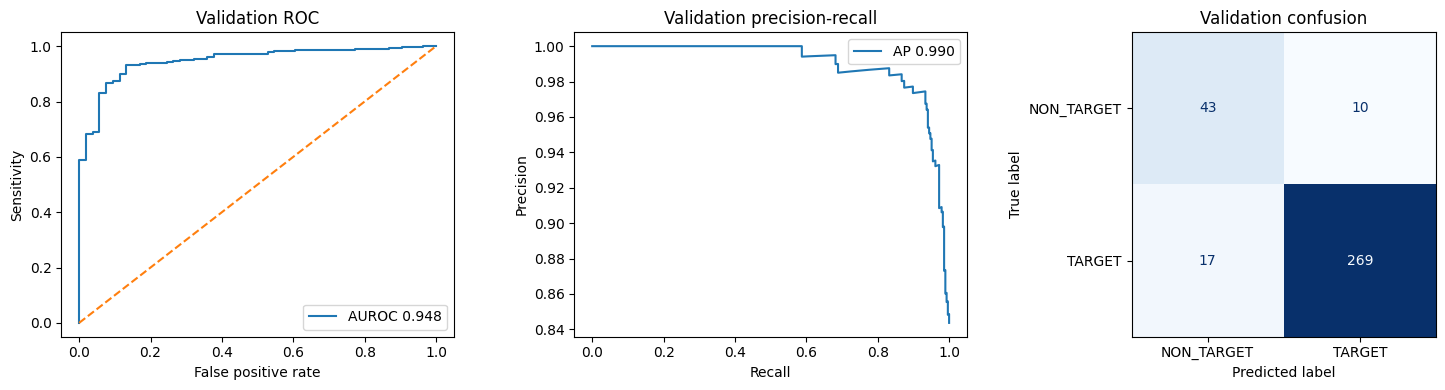

In [11]:
CHOSEN_STAGE = "EfficientNetB0__head"
LOCK_SELECTION = True

lock_path = RUN_DIR / "locked_selection.json"
locked_model_path = RUN_DIR / "final_model_locked.keras"

if not LOCK_SELECTION:
    print("No model has been locked. Review the validation results first.")
else:
    if CHOSEN_STAGE not in stage_checkpoints:
        raise ValueError("CHOSEN_STAGE must be one of the saved stages listed above")
    if lock_path.exists() or locked_model_path.exists():
        raise FileExistsError("A model is already locked for this run. Do not overwrite it.")
    if (RUN_DIR / "final_test_once").exists():
        raise RuntimeError("The test has already been opened for this run")
    chosen = stage_predictions[CHOSEN_STAGE]
    chosen_op = choose_threshold(chosen)
    chosen_threshold = float(chosen_op["threshold"])
    shutil.copy2(stage_checkpoints[CHOSEN_STAGE], locked_model_path)
    lock = {
        "stage": CHOSEN_STAGE,
        "architecture": CHOSEN_STAGE.split("__")[0],
        "model_file": locked_model_path.name,
        "model_sha256": sha256(locked_model_path),
        "threshold": chosen_threshold,
        "specificity_floor_used_in_validation": MIN_SPECIFICITY,
        "validation_metrics": chosen_op,
        "train_sha256": train_hash, "validation_sha256": val_hash,
        "source_checkpoint_sha256": sha256(stage_checkpoints[CHOSEN_STAGE]),
        "note": "Selected using conventional validation images. Not validated for clinical use or PWA.",
    }
    lock_path.write_text(json.dumps(lock, indent=2) + "\n")
    print("Locked:", CHOSEN_STAGE)
    print("Validation threshold:", round(chosen_threshold, 5))
    print("Saved the model and selection details. The test set is still sealed.")
    print("Results by clinical group:")
    display(clinical_report(chosen, chosen_threshold).round(3))
    print("Results by source:")
    display(group_metrics(chosen, chosen_threshold, "dataset_source").round(3))

    y = chosen["binary_label"].to_numpy(dtype=int)
    scores = chosen["probability_target"].to_numpy(dtype=float)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    fpr, tpr, _ = roc_curve(y, scores)
    ax[0].plot(fpr, tpr, label=f"AUROC {roc_auc_score(y, scores):.3f}")
    ax[0].plot([0, 1], [0, 1], "--")
    ax[0].set(title="Validation ROC", xlabel="False positive rate", ylabel="Sensitivity")
    ax[0].legend()
    precision, recall, _ = precision_recall_curve(y, scores)
    ax[1].plot(recall, precision, label=f"AP {average_precision_score(y, scores):.3f}")
    ax[1].set(title="Validation precision-recall", xlabel="Recall", ylabel="Precision")
    ax[1].legend()
    ConfusionMatrixDisplay.from_predictions(
        y, (scores >= chosen_threshold).astype(int), labels=[0, 1],
        display_labels=["NON_TARGET", "TARGET"], cmap="Blues", ax=ax[2], colorbar=False)
    ax[2].set_title("Validation confusion")
    fig.tight_layout()
    fig.savefig(RUN_DIR / "locked_validation_plots.png", dpi=150)
    plt.show()

## 10. Final conventional test — leave this off at first

**Do not run the final test until the model and threshold are locked and you have reviewed the validation results.**

The test is disabled by default. Turning it on is a one-time decision. After you open it, **do not change the model, threshold, or training plan because of the test results**.

This is still a test on ordinary light-appearing-skin photographs, **not a PWA test**.

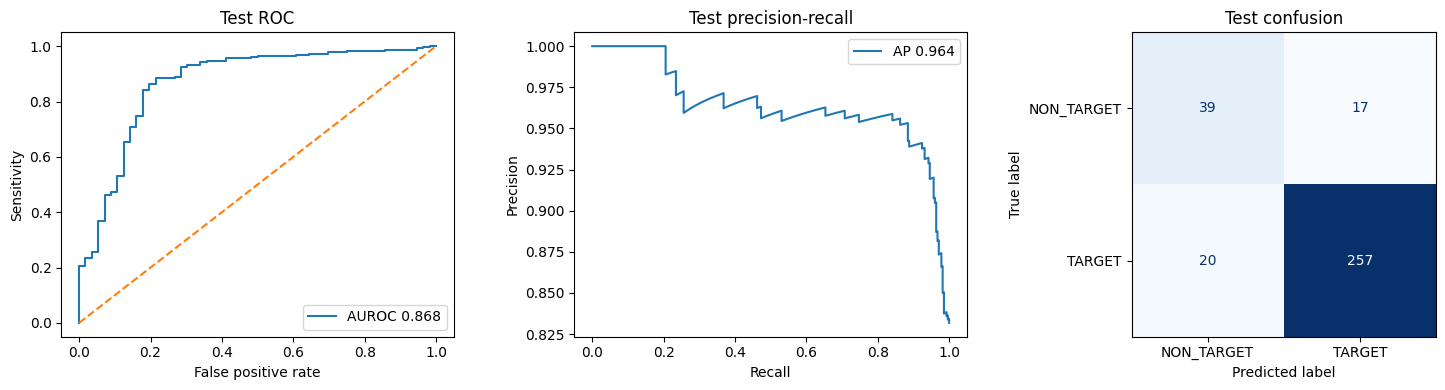

Final conventional test at the locked threshold: 0.37495


,sensitivity,specificity,auroc,average_precision,false_negatives,false_positives
0,0.9278,0.6964,0.8681,0.9638,20,17


By diagnosis:


,diagnostic,images,target_images,non_target_images,true_positives,false_positives,true_negatives,false_negatives,sensitivity,specificity,threshold,auroc,average_precision
0,ACK,24,24,0,23,0,0,1,0.958,NaN,0.375,None,None
1,AKIEC,7,7,0,7,0,0,0,1.000,NaN,0.375,None,None
2,BCC,189,189,0,184,0,0,5,0.974,NaN,0.375,None,None
3,BKL,13,0,13,0,8,5,0,NaN,0.385,0.375,None,None
4,MEL,21,21,0,8,0,0,13,0.381,NaN,0.375,None,None
5,NEV,8,0,8,0,2,6,0,NaN,0.750,0.375,None,None
6,NV,34,0,34,0,6,28,0,NaN,0.824,0.375,None,None
7,SCC,23,23,0,22,0,0,1,0.957,NaN,0.375,None,None
8,SCCKA,13,13,0,13,0,0,0,1.000,NaN,0.375,None,None
9,SEK,1,0,1,0,1,0,0,NaN,0.000,0.375,None,None


By source:


,dataset_source,images,target_images,non_target_images,true_positives,false_positives,true_negatives,false_negatives,sensitivity,specificity,threshold,auroc,average_precision
0,MILK10K,190,143,47,127,14,33,16,0.888,0.702,0.375,0.807,0.900
1,PAD_UFES_20,143,134,9,130,3,6,4,0.970,0.667,0.375,0.962,0.997


Test files saved to: /content/drive/MyDrive/SkinX/models/runs/notebook_04/three_models_finetune_v1/final_test_once
Do not tune the model using these results. Notebook 05 handles PWA evaluation and adaptation.


In [12]:
RUN_FINAL_TEST = True
TEST_CONFIRMATION = "I_HAVE_LOCKED_MY_MODEL_AND_THRESHOLD"

if not RUN_FINAL_TEST:
    print("The test set is still sealed.")
elif TEST_CONFIRMATION != "I_HAVE_LOCKED_MY_MODEL_AND_THRESHOLD":
    raise ValueError("Read the test instructions and enter the confirmation phrase first")
elif not lock_path.is_file() or not locked_model_path.is_file():
    raise FileNotFoundError("Lock the model and validation threshold before opening the test")
else:
    # No test file is read anywhere before this branch.
    test_path = SPLIT_DIR / "skinX_test_manifest_v1.csv"
    test_dir = RUN_DIR / "final_test_once"
    if test_dir.exists():
        raise FileExistsError("The test has already been run for this experiment")
    saved_lock = json.loads(lock_path.read_text(encoding="utf-8"))
    if sha256(locked_model_path) != saved_lock["model_sha256"]:
        raise ValueError("The locked checkpoint has changed")
    if sha256(TRAIN_PATH) != saved_lock["train_sha256"] or sha256(VAL_PATH) != saved_lock["validation_sha256"]:
        raise ValueError("Training or validation files have changed since the model was locked")
    if not test_path.is_file():
        raise FileNotFoundError(f"Missing test file: {test_path}")
    test_df = pd.read_csv(test_path)
    check_manifest(test_df, "Test")
    for col in ["image_id", "md5_hash", "group_id"]:
        if set(test_df[col]) & (set(train_df[col]) | set(val_df[col])):
            raise ValueError(f"Possible data leakage into the test set through {col}")

    threshold = float(saved_lock["threshold"])
    test_ds = make_dataset(test_df, training=False)
    final_model = models.load_model(locked_model_path, compile=False)
    test_dir.mkdir()  # Reserve the folder before predicting so this cannot silently run twice.
    test_scores = final_model.predict(test_ds, verbose=0).reshape(-1)
    if len(test_scores) != len(test_df) or not np.isfinite(test_scores).all():
        raise ValueError("Invalid test prediction count or values")
    test_pred = test_df.copy()
    test_pred["probability_target"] = test_scores
    test_pred["prediction_at_threshold"] = (test_scores >= threshold).astype(int)
    test_pred.to_csv(test_dir / "test_predictions.csv", index=False)
    result = metrics_at_threshold(test_pred, threshold)
    group_metrics(test_pred, threshold, "dataset_source").to_csv(
        test_dir / "test_by_source.csv", index=False)
    group_metrics(test_pred, threshold, "diagnostic").to_csv(
        test_dir / "test_by_diagnosis.csv", index=False)
    clinical_report(test_pred, threshold).to_csv(
        test_dir / "test_by_clinical_group.csv", index=False)
    if "diagnosis_full" in test_pred.columns:
        group_metrics(test_pred, threshold, "diagnosis_full").to_csv(
            test_dir / "test_by_full_diagnosis.csv", index=False)

    # Simple image-level uncertainty ranges. MILK10k has no patient IDs, so
    # these ranges do not correct for possible images from the same person.
    def wilson(success, total, z=1.96):
        if total == 0:
            return [None, None]
        rate = success / total
        denom = 1 + z*z/total
        center = (rate + z*z/(2*total)) / denom
        half = z * math.sqrt((rate*(1-rate) + z*z/(4*total))/total) / denom
        return [float(max(0, center-half)), float(min(1, center+half))]

    result["sensitivity_95pct_image_level"] = wilson(result["true_positives"], result["target_images"])
    result["specificity_95pct_image_level"] = wilson(result["true_negatives"], result["non_target_images"])
    result["test_sha256"] = sha256(test_path)
    result["model_sha256"] = saved_lock["model_sha256"]
    result["limitations"] = (
        "Ordinary light-appearing skin, not PWA; small diagnosis groups; "
        "MILK10k lacks patient IDs; class and source imbalance; "
        "image-level uncertainty ranges do not account for patient clustering."
    )
    (test_dir / "test_metrics.json").write_text(json.dumps(result, indent=2) + "\n")

    y = test_pred["binary_label"].to_numpy(dtype=int)
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))
    fpr, tpr, _ = roc_curve(y, test_scores)
    ax[0].plot(fpr, tpr, label=f"AUROC {roc_auc_score(y, test_scores):.3f}")
    ax[0].plot([0, 1], [0, 1], "--")
    ax[0].set(title="Test ROC", xlabel="False positive rate", ylabel="Sensitivity")
    ax[0].legend()
    precision, recall, _ = precision_recall_curve(y, test_scores)
    ax[1].plot(recall, precision, label=f"AP {average_precision_score(y, test_scores):.3f}")
    ax[1].set(title="Test precision-recall", xlabel="Recall", ylabel="Precision")
    ax[1].legend()
    ConfusionMatrixDisplay.from_predictions(
        y, (test_scores >= threshold).astype(int), labels=[0, 1],
        display_labels=["NON_TARGET", "TARGET"], cmap="Blues", ax=ax[2], colorbar=False)
    ax[2].set_title("Test confusion")
    fig.tight_layout()
    fig.savefig(test_dir / "test_plots.png", dpi=150)
    plt.show()

    print("Final conventional test at the locked threshold:", round(threshold, 5))
    display(pd.DataFrame([result])[["sensitivity", "specificity", "auroc", "average_precision",
                                    "false_negatives", "false_positives"]].round(4))
    print("By diagnosis:")
    display(group_metrics(test_pred, threshold, "diagnostic").round(3))
    print("By source:")
    display(group_metrics(test_pred, threshold, "dataset_source").round(3))
    print("Test files saved to:", test_dir)
    print("Do not tune the model using these results. Notebook 05 handles PWA evaluation and adaptation.")

## 11. What gets saved

Each stage has its own folder under `MyDrive/SkinX/models/runs/notebook_04/<RUN_TAG>/`. The folders contain the checkpoint (for new training stages), training history and curves, validation predictions, validation metrics, and results by source and diagnosis. The baseline stage points to the original Notebook 03 checkpoint rather than copying it.

The main folder also keeps the run settings and a comparison of every stage. A model is only copied to `final_model_locked.keras` when you explicitly lock it. The test results go into `final_test_once/` **only when you turn on the final test**.

**Things to check before moving on:** Is melanoma sensitivity still low? Do PAD and MILK10k behave differently? Is the model making too many false positives? Are differences based on very small groups? If the model is not strong enough, document that rather than calling it clinically reliable.

Notebook 05 is a separate experiment. It first measures how the conventional model performs on suitable PWA cases, then tries PWA fine-tuning **using different PWA cases from the ones reserved for evaluation**.